In [9]:
import pandas as pd

DATA_PATH = "../data/raw/"
PROCESSED_PATH = "../data/processed/"

orders = pd.read_csv(DATA_PATH + "orders.csv")
order_products_prior = pd.read_csv(DATA_PATH + "order_products__prior.csv")
products = pd.read_csv(DATA_PATH + "products.csv")
departments = pd.read_csv(DATA_PATH + "departments.csv")

user_clusters = pd.read_csv(
    PROCESSED_PATH + "user_clusters.csv"
)

In [10]:
user_orders = orders[[
    "order_id",
    "user_id"
]]

order_detail = order_products_prior.merge(
    user_orders,
    on="order_id",
    how="left"
)

order_detail = order_detail.merge(
    products,
    on="product_id",
    how="left"
)

order_detail = order_detail.merge(
    departments,
    on="department_id",
    how="left"
)

order_detail = order_detail.merge(
    user_clusters[[
        "user_id",
        "cluster"
    ]],
    on="user_id",
    how="left"
)

In [11]:
order_detail

,order_id,product_id,add_to_cart_order,reordered,user_id,product_name,aisle_id,department_id,department,cluster
0,2,33120,1,1,202279,Organic Egg Whites,86,16,dairy eggs,1
1,2,28985,2,1,202279,Michigan Organic Kale,83,4,produce,1
2,2,9327,3,0,202279,Garlic Powder,104,13,pantry,1
3,2,45918,4,1,202279,Coconut Butter,19,13,pantry,1
4,2,30035,5,0,202279,Natural Sweetener,17,13,pantry,1
...,...,...,...,...,...,...,...,...,...,...
32434484,3421083,39678,6,1,25247,Free & Clear Natural Dishwasher Detergent,74,17,household,2
32434485,3421083,11352,7,0,25247,Organic Mini Sandwich Crackers Peanut Butter,78,19,snacks,2
32434486,3421083,4600,8,0,25247,All Natural French Toast Sticks,52,1,frozen,2
32434487,3421083,24852,9,1,25247,Banana,24,4,produce,2


In [12]:
cluster_department = (
    order_detail
    .groupby(["cluster", "department"])
    .size()
    .reset_index(name="count")
)

cluster_department.head()

,cluster,department,count
0,0,alcohol,31430
1,0,babies,41158
2,0,bakery,136927
3,0,beverages,310668
4,0,breakfast,79306


In [13]:
cluster_department[
    cluster_department["cluster"] == 1
].sort_values(
    by="count",
    ascending=False
).head(10)

,cluster,department,count
40,1,produce,1024498
28,1,dairy eggs,587853
41,1,snacks,320366
24,1,beverages,305982
31,1,frozen,302312
37,1,pantry,245808
27,1,canned goods,148446
23,1,bakery,136606
29,1,deli,125703
30,1,dry goods pasta,119398


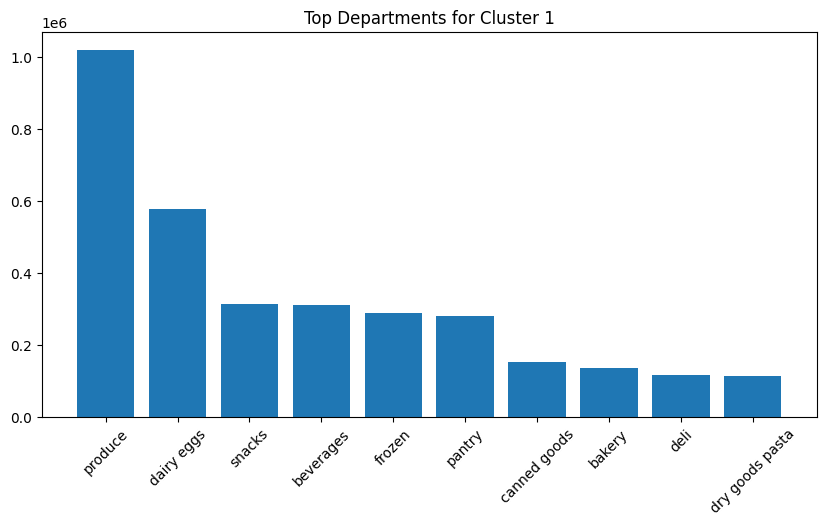

In [14]:
import matplotlib.pyplot as plt

top_dept = (
    cluster_department[
        cluster_department["cluster"] == 0
    ]
    .sort_values(by="count", ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))

plt.bar(
    top_dept["department"],
    top_dept["count"]
)

plt.title("Top Departments for Cluster 1")

plt.xticks(rotation=45)

plt.show()

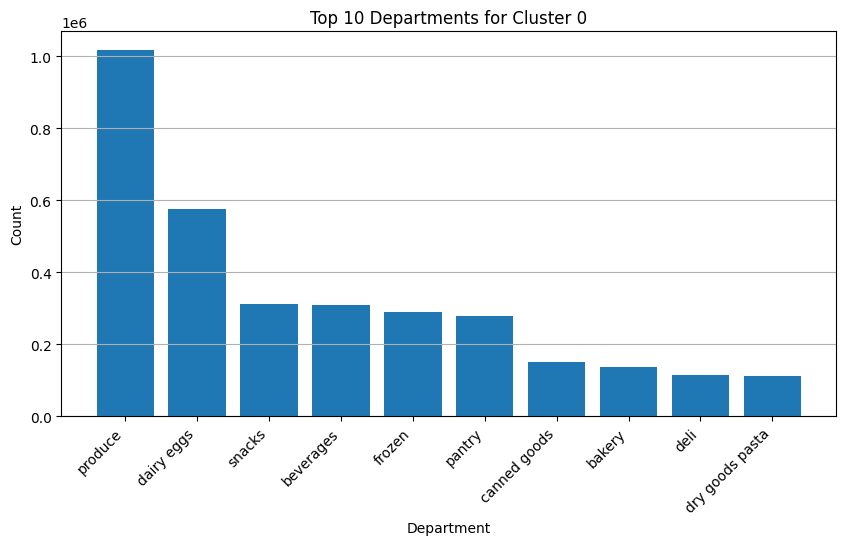

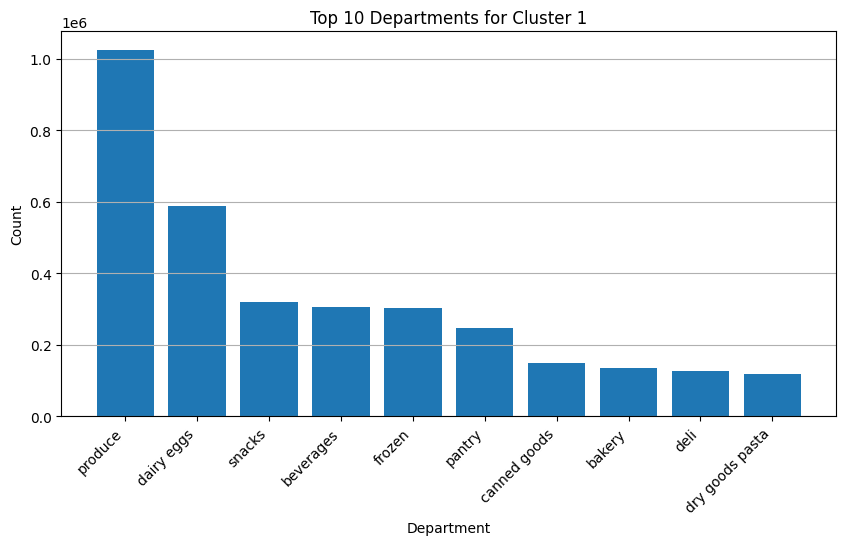

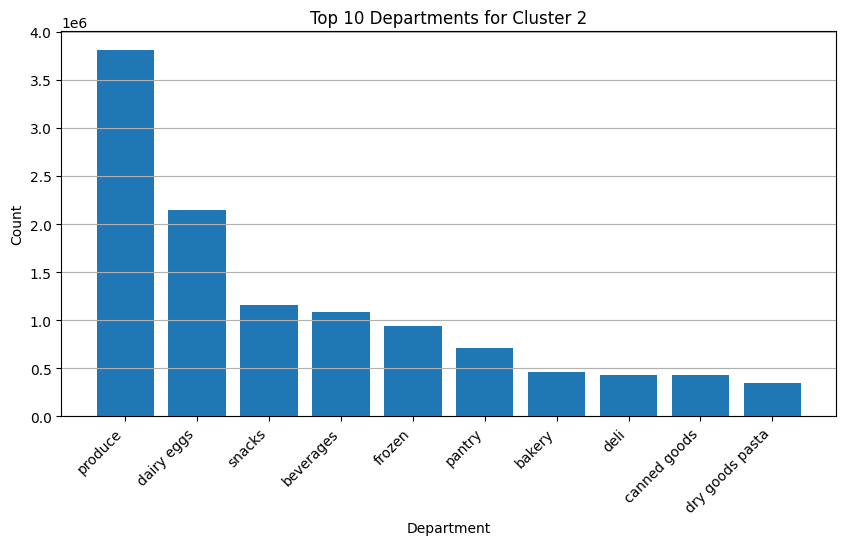

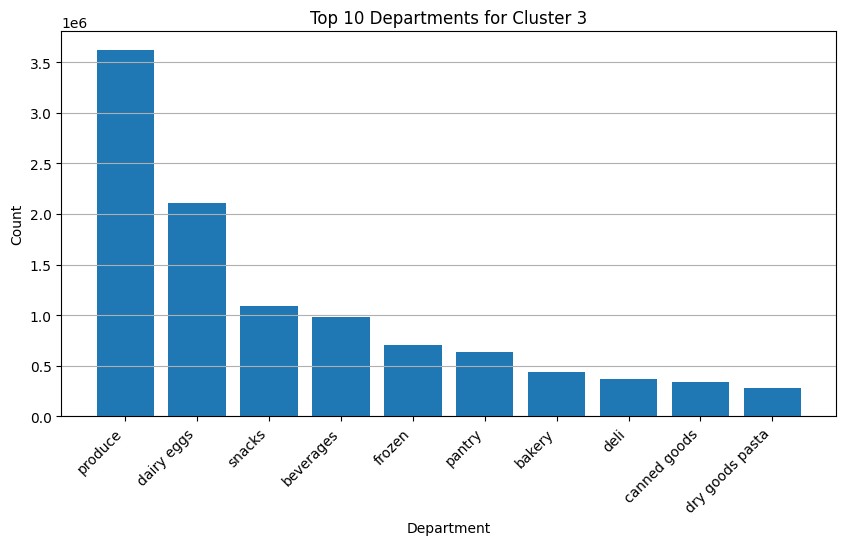

In [15]:
import matplotlib.pyplot as plt

cluster_department = (
    order_detail
    .groupby(["cluster", "department"])
    .size()
    .reset_index(name="count")
)

for cluster_id in range(4):
    top_dept = (
        cluster_department[cluster_department["cluster"] == cluster_id]
        .sort_values(by="count", ascending=False)
        .head(10)
    )

    plt.figure(figsize=(10, 5))
    plt.bar(top_dept["department"], top_dept["count"])

    plt.title(f"Top 10 Departments for Cluster {cluster_id}")
    plt.xlabel("Department")
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y")

    plt.show()

In [17]:
cluster_product_count = (
    order_detail
    .groupby(["cluster", "product_name"])
    .size()
    .reset_index(name="count")
)

cluster_total_count = (
    cluster_product_count
    .groupby("cluster")["count"]
    .transform("sum")
)

cluster_product_count["ratio"] = (
    cluster_product_count["count"] / cluster_total_count
)

cluster_product_ratio = cluster_product_count

cluster_product_ratio.head()

,cluster,product_name,count,ratio
0,0,#2 Coffee Filters,65,1.706465e-05
1,0,#2 Cone White Coffee Filters,3,7.875994e-07
2,0,#4 Natural Brown Coffee Filters,23,6.038262e-06
3,0,& Go! Hazelnut Spread + Pretzel Sticks,31,8.138527e-06
4,0,'Swingtop' Premium Lager,1,2.625331e-07


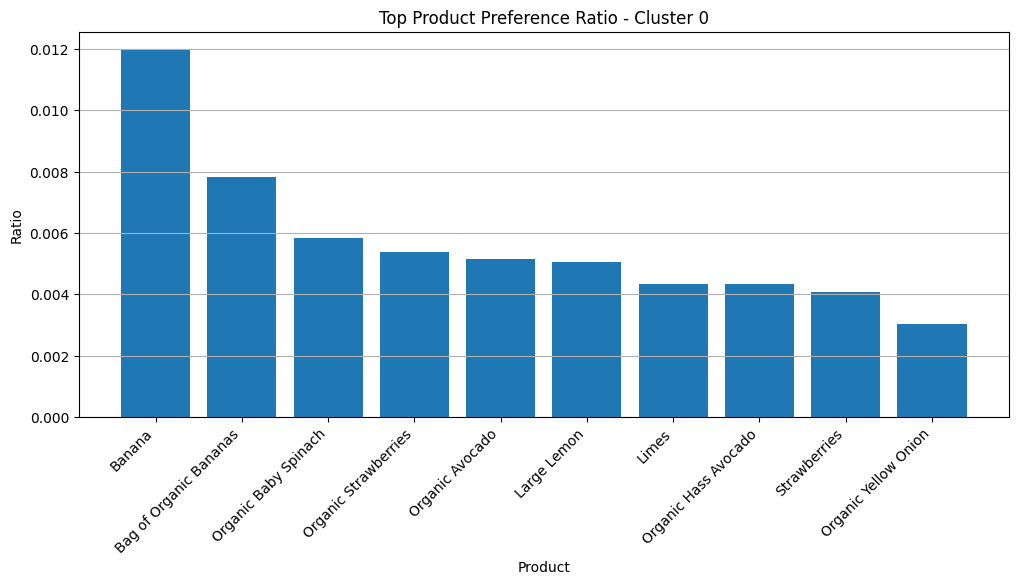

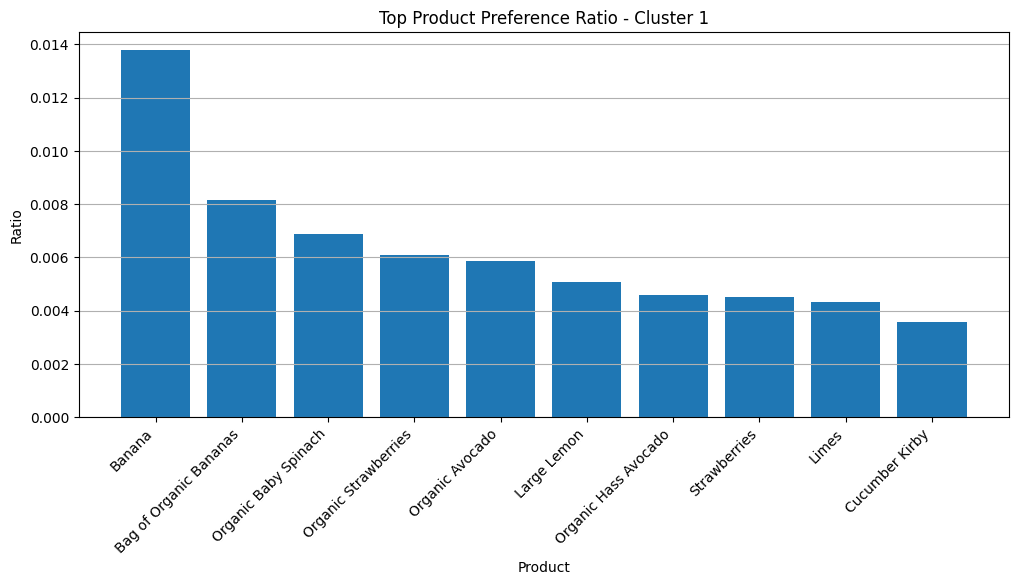

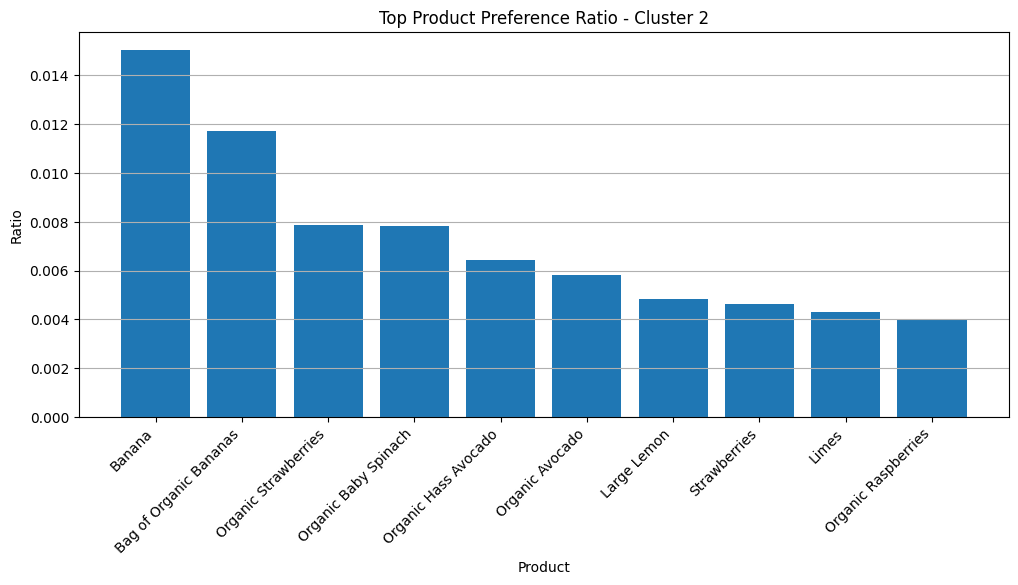

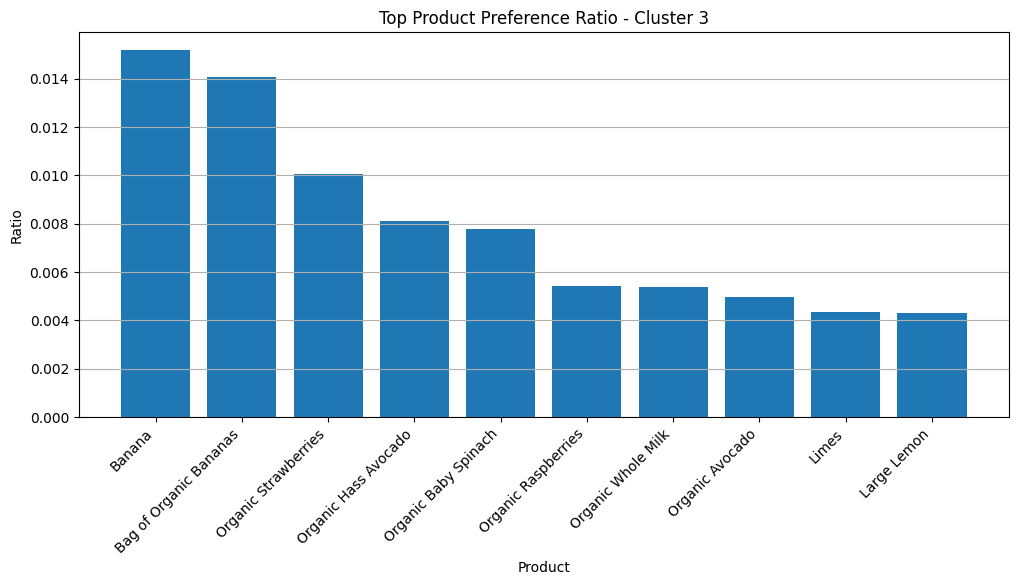

In [18]:
import matplotlib.pyplot as plt

for cluster_id in range(4):
    top_products = (
        cluster_product_ratio[
            cluster_product_ratio["cluster"] == cluster_id
        ]
        .sort_values(by="ratio", ascending=False)
        .head(10)
    )

    plt.figure(figsize=(12, 5))
    plt.bar(top_products["product_name"], top_products["ratio"])

    plt.title(f"Top Product Preference Ratio - Cluster {cluster_id}")
    plt.xlabel("Product")
    plt.ylabel("Ratio")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y")

    plt.show()